In [1]:
import numpy as np
from amuse.ic.kroupa import new_kroupa_mass_distribution
from amuse.units import units
from amuse.ic.salpeter import new_salpeter_mass_distribution
import matplotlib.pyplot as plt
from amuse.lab import nbody_system

In [10]:
number_of_stars = 250
mass_min = 0.08 | units.MSun
mass_max = 30 | units.MSun

mass_kroupa = new_kroupa_mass_distribution(number_of_stars, mass_min=mass_min, mass_max=mass_max)
mass_salpeter = new_salpeter_mass_distribution(number_of_stars, mass_min=mass_min, mass_max=mass_max)

print(mass_kroupa)
print(mass_salpeter)

[0.1714821186, 0.50566704158, 2.8062522254, 0.252736350181, 0.135132343743, 0.0931282391327, 0.16083086838, 0.487711886648, 0.0870148739641, 0.68886116454, 0.308747058148, 0.167664610387, 0.190925542459, 0.287828456499, 0.285147242983, 0.701104108073, 1.97876560305, 0.0934079337318, 0.294886205964, 0.0850350540797, 2.19832401414, 0.169777476819, 0.562673689081, 0.167688684228, 0.229914318265, 0.108912607331, 0.317438622819, 0.0953712624636, 0.139785376263, 0.154062896507, 0.363215725354, 0.438194314596, 0.1842353061, 0.188596357232, 0.178681506154, 2.68883255169, 0.217478743117, 0.875401615792, 0.0931943247261, 0.190678479073, 0.107706274585, 0.0878727246532, 0.454044843971, 0.444520465969, 0.121833051329, 3.76878575791, 2.3267876003, 0.0916386676429, 0.148564909673, 1.1599296036, 0.974077799826, 0.816950334856, 0.603679019522, 0.163279268569, 0.0994489106438, 0.251348089146, 1.5632602744, 0.0890645457788, 0.153424739724, 0.181009445684, 0.369845101334, 1.00926040359, 0.456886967908, 0

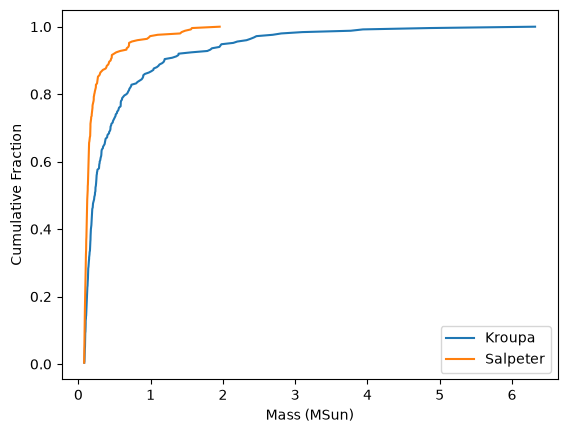

In [11]:
for mass in [mass_kroupa, mass_salpeter]:
    sorted_masses = np.sort(mass.value_in(units.MSun))
    arranged_data = np.arange(1, len(mass)+1) / len(mass)
    plt.plot(sorted_masses, arranged_data, label="Kroupa" if mass is mass_kroupa else "Salpeter")
plt.xlabel("Mass (MSun)")
plt.ylabel("Cumulative Fraction")
plt.legend()
plt.show()

In [12]:
mass_scale = mass_kroupa.sum()
print(mass_scale.in_(units.MSun))
length_scale = 0.5 | units.parsec #sets virial radius
converter = nbody_system.nbody_to_si(mass_scale, length_scale) #converts to si units

130.073527576 MSun


                 key         mass       radius           vx           vy           vz            x            y            z
                   -           kg            m    m * s**-1    m * s**-1    m * s**-1            m            m            m
====================  ===========  ===========  ===========  ===========  ===========  ===========  ===========  ===========
 3367092543448957020    1.035e+30    0.000e+00   -1.749e+02   -1.120e+03   -2.073e+02   -3.923e+16   -7.696e+15   -3.035e+16
12399898751320565346    1.035e+30    0.000e+00    2.804e+02    5.065e+02    5.997e+02    7.166e+16   -5.738e+14    3.876e+16
 8430031706624091531    1.035e+30    0.000e+00    2.699e+02    5.301e+02    6.070e+02    7.203e+16   -1.017e+15    3.771e+16
16753109715235729274    1.035e+30    0.000e+00   -4.006e+02   -8.306e+02    4.013e+01   -3.983e+16   -8.553e+15   -2.856e+16
10308047176757855988    1.035e+30    0.000e+00   -2.610e+02   -6.515e+02    7.455e+01   -4.397e+16   -6.921e+15   -3.670e+16


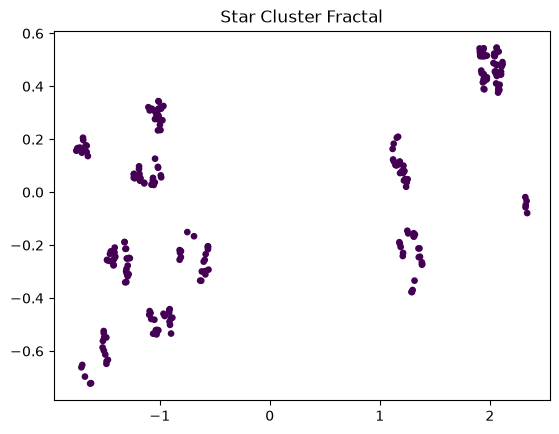

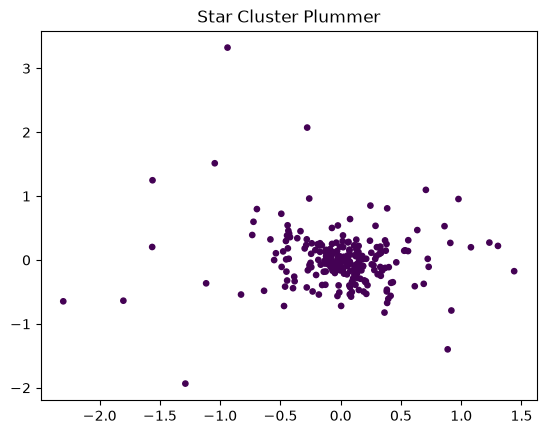

In [13]:
#starcluster stuff
from amuse.ic.fractalcluster import new_fractal_cluster_model
from amuse.ic.plummer import new_plummer_model

particles_fractal = new_fractal_cluster_model(number_of_stars, converter, fractal_dimension=1.0)
particles_plummer = new_plummer_model(number_of_stars, converter)

print(particles_fractal, particles_fractal.mass.sum().in_(units.MSun))
print(particles_plummer, particles_plummer.mass.sum().in_(units.MSun))

for particles in [particles_fractal, particles_plummer]:
    plt.scatter(particles.x.value_in(units.parsec), particles.y.value_in(units.parsec), s=20*np.sqrt(particles.mass.value_in(units.MSun)), c = np.log10(np.sqrt(particles.mass.value_in(units.MSun))))
    plt.title("Star Cluster{}".format(" Fractal" if particles is particles_fractal else " Plummer"))
    plt.show()

In [14]:
from amuse.lab import Particles

print(dir(particles_fractal))
Q_vir_fractal = particles_fractal.kinetic_energy() / (particles_fractal.potential_energy()) #virial ratio
print("Fractal cluster virial ratio:", Q_vir_fractal)

Q_vir = 0.25
converter = nbody_system.nbody_to_si(0.2 | units.parsec, particles_fractal.mass.sum())
particles_fractal.scale_to_standard(converter, virial_ratio=Q_vir)
Q_vir_fractal = particles_fractal.kinetic_energy() / (particles_fractal.potential_energy())
print("Fractal cluster virial ratio after scaling:", Q_vir_fractal)

['GLOBAL_DERIVED_ATTRIBUTES', 'LagrangianRadii', 'Qparameter', '__add__', '__array__', '__array_interface__', '__array_struct__', '__class__', '__contains__', '__delattr__', '__dict__', '__dir__', '__doc__', '__eq__', '__firstlineno__', '__format__', '__ge__', '__getattr__', '__getattribute__', '__getitem__', '__getstate__', '__gt__', '__hash__', '__init__', '__init_subclass__', '__iter__', '__le__', '__len__', '__lt__', '__module__', '__ne__', '__new__', '__or__', '__reduce__', '__reduce_ex__', '__repr__', '__setattr__', '__sizeof__', '__static_attributes__', '__str__', '__sub__', '__subclasshook__', '__weakref__', '_add_indices_in_attribute_storage', '_as_masked_subset_in', '_attributes_for_dir', '_convert_from_entities_or_quantities', '_convert_to_entities_or_quantities', '_convert_to_entities_or_quantities_async', '_convert_to_entity_or_quantity', '_factory_for_new_collection', '_get_derived_attribute_value', '_get_particle', '_get_particle_unsave', '_get_value_of_attribute', '_get

In [23]:
def compute_energy(particles):
    return particles.kinetic_energy() + particles.potential_energy()

In [ ]:
#initializing gravitational code: (many different gravitational codes available in AMUSE)

import code

from amuse.community.ph4.interface import Ph4 #good for cluster simulations but accumulates energy errors poorly
from amuse.community.huayno.interface import Huayno #good for planetary systems and debris disks (any system you evolve for many dynamical timescales)

def compute_energy(particles):
    return particles.kinetic_energy() + particles.potential_energy()

for label, integrator in [("Ph4", Ph4), ("Huayno", Huayno)]:
    print(f"Integrating {label}")
    code = integrator(converter, number_of_works =4)
    code.particles.add_particles(particles_fractal) #add the fractal cluster particles to the gravitational code
    print(dir(code))
    code.parameters.epsilon_squared = (0 | units.au)**2 #set the softening length squared for the gravitational code
    code.parameters.timestep_parameter = 0.1 #set the timestep parameter for the gravitational code. tunes how how high you want the resolution to be. timescale is dictated by collision timescale between any two particles. has eta in front of it. smaller eta, smaller the timescale (more accurate but slower)
    if label == "Huayno":
        code.parameters.integrator = "SHARED4"

    time = 0 | units.yr #initialize the simulation time to zero years
    end_time = 0.1 | units.Myr
    dt = end_time/10

    from amuse.ext.LagrangianRadii import LagrangianRadii #import the function to calculate Lagrangian radii of the cluster
    import time as cpu_time
    start_time = cpu_time.time()

    initial_energy = compute_energy(code.particles) #store the initial energy of the system

    while time < end_time:
        time += dt
        code.evolve_model(time)
        print(f'code time: {code.model_time.in_(units.Myr)}')
        energy = computer_energy(code.particles)
        dE = abs(energy - initial_energy) / initial_energy #energy error
        print(f'energy: {energy}, dE: {dE}')
        half_mass_radius = LagrangianRadii(code.particles)[6]
        print(f'half-mass radius: {half_mass_radius}')

    end_time = cpu_time.time()
    print(f'time taken: {end_time - start_time}')
    code.stop() #very important so code doesnt keep running in background

Integrating Ph4
['MODE_CPU', 'MODE_GPU', 'NBODY', '__class__', '__del__', '__delattr__', '__dict__', '__dir__', '__doc__', '__eq__', '__firstlineno__', '__format__', '__ge__', '__getattr__', '__getattribute__', '__getstate__', '__gt__', '__hash__', '__init__', '__init_handlers__', '__init_subclass__', '__le__', '__lt__', '__module__', '__ne__', '__new__', '__reduce__', '__reduce_ex__', '__repr__', '__setattr__', '__setstate__', '__sizeof__', '__static_attributes__', '__str__', '__subclasshook__', '__weakref__', '_check_if_worker_is_up_to_date', '_create_new_grid', '_handlers', '_local_options', '_options', '_start', '_stop', '_stop_worker', 'all_literature_references_string', 'async_request', 'before_get_data_store_names', 'before_get_parameter', 'before_new_set_instance', 'before_set_interface_parameter', 'before_set_parameter', 'center_of_mass_position', 'center_of_mass_velocity', 'channel', 'channel_factory', 'channel_type', 'classes', 'cleanup_code', 'commit_parameters', 'commit_pa

In [34]:
from amuse.ext.orbital_elements import orbital_elements, new_binary_from_orbital_elements
from amuse.units import constants

def print_kepler_elements(binary):
    kepler_elements = orbital_elements(binary, G=constants.G)
    mass_a = kepler_elements[0]
    mass_b = kepler_elements[1]
    semi_major_axis = kepler_elements[2]
    eccentricity = kepler_elements[3]
    peri = semi_major_axis * (1 - eccentricity)
    true_anomaly = kepler_elements[4]
    inclination = kepler_elements[5]
    longitude_of_the_ascending_node = kepler_elements[6]
    argument_of_periapsis = kepler_elements[7]

    print(f'kepler elments:')
    print(f'Mass A: {mass_a.in_(units.MSun)}')
    print(f'Mass B: {mass_b.in_(units.MSun)}')
    print(f'Semi-major axis: {semi_major_axis.in_(units.au)}')
    print(f'Eccentricity: {eccentricity}')
    print(f'Periapsis distance: {peri.in_(units.au)}')
    print(f'True anomaly: {true_anomaly.in_(units.deg)}')
    print(f'Inclination: {inclination.in_(units.deg)}')
    print(f'Longitude of the ascending node: {longitude_of_the_ascending_node.in_(units.deg)}')
    print(f'Argument of periapsis: {argument_of_periapsis.in_(units.deg)}')
    print(f'='*40)

particles_fractal.move_to_center()
particles_fractal.radius = 1 | units.au

particles_with_binary = particles_fractal.copy()
print(particles_with_binary[:3])

most_massive_particle = particles_with_binary[particles_with_binary.mass.argmax()]
#print(f'Most massive particle: {most_massive_particle}')

q = 1/3 #mass ratio
mass_a = q* most_massive_particle.mass
mass_b = most_massive_particle.mass - mass_a
binary = new_binary_from_orbital_elements(
    mass1=mass_a,
    mass2=mass_b,
    semimajor_axis=100 | units.au,
    eccentricity=0.6,
    true_anomaly=0,
    inclination=0 | units.deg,
    longitude_of_the_ascending_node=0 | units.deg,
    argument_of_periapsis=0 | units.deg,
    G=None
)
print(binary)
print_kepler_elements(binary)

print(binary.position.in_(units.au), binary.velocity.in_(units.kms))
print(most_massive_particle.position.in_(units.au), most_massive_particle.velocity.in_(units.kms))

binary.position += most_massive_particle.position #shifts posistion of the binary to the position of the most massive particle
binary.velocity += most_massive_particle.velocity #shifts velocity of the binary to the velocity of the most massive particle

print(binary.position.in_(units.au), binary.velocity.in_(units.kms)) #print the updated position and velocity of the binary

print(len(particles_with_binary))
particles_with_binary.add_particles(binary) #add the binary to the particle set
print(len(particles_with_binary))
particles_with_binary.remove_particle(most_massive_particle) #remove the most massive particle from the particle set so it stays a binary
print(particles_with_binary)


                 key         mass       radius           vx           vy           vz            x            y            z
                   -           kg            m    m * s**-1    m * s**-1    m * s**-1            m            m            m
====================  ===========  ===========  ===========  ===========  ===========  ===========  ===========  ===========
 3367092543448957020    1.035e+30    1.496e+11   -1.955e+02   -1.253e+03   -2.318e+02   -1.569e+16   -3.078e+15   -1.214e+16
12399898751320565346    1.035e+30    1.496e+11    3.135e+02    5.663e+02    6.705e+02    2.867e+16   -2.295e+14    1.551e+16
 8430031706624091531    1.035e+30    1.496e+11    3.017e+02    5.927e+02    6.786e+02    2.881e+16   -4.069e+14    1.508e+16
====================  ===========  ===========  ===========  ===========  ===========  ===========  ===========  ===========
                 key         mass           vx           vy           vz            x            y            z
             

/Users/emorymurff/anaconda3/envs/amuse/lib/python3.14/site-packages/amuse/ext/orbital_elements.py:344: UserWarning: new_binary_from_orbital_elements is deprecated, use generate_binaries instead
  warnings.warn(


In [35]:
#Ph4 with new binary and collision
code = Ph4(converter, number_of_works =4)
code.particles.add_particles(particles_with_binary)
code.parameters.epsilon_squared = (0 | units.au)**2 #set the softening length squared for the gravitational code
code.parameters.timestep_parameter = 0.1 #set the timestep parameter for the gravitational code. tunes how how high you want the resolution to be. timescale is dictated by collision timescale between any two particles. has eta in front of it. smaller eta, smaller the timescale (more accurate but slower)
print(code.particles.radius)

gc = code.stopping_conditions.collision_detection
gc.enable() #enable the collision detection stopping condition (will check every timestep for collisions)

channel = code.particles.new_channel_to(particles_with_binary) #direct communication between the base code and the local particle set

start_time = cpu_time.time()
time = 0 | units.yr #initialize the simulation time to zero years
end_time = 0.1 | units.Myr
dt = end_time/10

initial_energy = compute_energy(code.particles) #store the initial energy of the system
initial_energy_local = compute_energy(particles_with_binary)

def resolve_collision(colliding_set, code_particle_set): #resolve a collision by merging the colliding particles into a single particle
    print_kepler_elements(colliding_set)

    new_mass = colliding_set.mass.sum()
    new_pos = colliding_set.center_of_mass()
    new_vel = colliding_set.center_of_mass_velocity()

    new_particle = Particles(1)
    new_particle.mass = new_mass
    new_particle.position = new_pos
    new_particle.velocity = new_vel
    new_particle.radius = colliding_set.radius.sum()

    code_particle_set.remove_particles(colliding_set)
    code_particle_set.add_particle(new_particle)
    return

while time < end_time:
    time += dt
    code.evolve_model(time)

    if gc.is_set(): #if collision detected
        print(f"Collision detected at {code.model_time.in_(units.yr)}")
        for ci in range(len(gc.particles(0))):
            colliding_particles = Particles(particles = [gc.particles(0)[ci], gc.particles(1)[ci]])
            print(f"Colliding particles: {colliding_particles}")
            print(f'collision occured at time {code.model_time.in_(units.Myr)}')
            print(f'# particles before collision: {len(code.particles)}')
            print(print_kepler_elements(colliding_particles))
            resolve_collision(colliding_particles, code.particles)
            print(f'# particles after collision: {len(code.particles)}')

    channel.copy() #update the local particle set with the current state from the base code

    print(f'code time: {code.model_time.in_(units.Myr)}')
    energy = compute_energy(code.particles)
    dE = abs(energy - initial_energy) / initial_energy #energy error
    print(f'energy: {energy}, dE: {dE}')
    dE_local = abs(compute_energy(particles_with_binary) - initial_energy_local) / initial_energy_local
    print(f'energy local: {compute_energy(particles_with_binary)}, dE local: {dE_local}')
    half_mass_radius = LagrangianRadii(code.particles)[6]
    print(f'half-mass radius: {half_mass_radius.in_(units.pc)}')

end_time = cpu_time.time()
print(f'time taken: {end_time - start_time}')
code.stop() #very important so code doesnt keep running in background

[149597870691.0, 149597870691.0, 149597870691.0, 149597870691.0, 149597870691.0, 149597870691.0, 149597870691.0, 149597870691.0, 149597870691.0, 149597870691.0, 149597870691.0, 149597870691.0, 149597870691.0, 149597870691.0, 149597870691.0, 149597870691.0, 149597870691.0, 149597870691.0, 149597870691.0, 149597870691.0, 149597870691.0, 149597870691.0, 149597870691.0, 149597870691.0, 149597870691.0, 149597870691.0, 149597870691.0, 149597870691.0, 149597870691.0, 149597870691.0, 149597870691.0, 149597870691.0, 149597870691.0, 149597870691.0, 149597870691.0, 149597870691.0, 149597870691.0, 149597870691.0, 149597870691.0, 149597870691.0, 149597870691.0, 149597870691.0, 149597870691.0, 149597870691.0, 149597870691.0, 149597870691.0, 149597870691.0, 149597870691.0, 149597870691.0, 149597870691.0, 149597870691.0, 149597870691.0, 149597870691.0, 149597870691.0, 149597870691.0, 149597870691.0, 149597870691.0, 149597870691.0, 149597870691.0, 149597870691.0, 149597870691.0, 149597870691.0, 1495978

In [ ]:
#Ph4 with new binary with collisions


In [ ]:
##inclass 2

                 key         mass         name           vx           vy           vz            x            y            z
                   -  1.98892e+30 * kg         none  3646245880.3572216 * m * s**-1  3646245880.3572216 * m * s**-1  3646245880.3572216 * m * s**-1  149597870691.0 * m  149597870691.0 * m  149597870691.0 * m
====================  ===========  ===========  ===========  ===========  ===========  ===========  ===========  ===========
16924140712456809094    1.000e+00          Sun    0.000e+00   -8.012e-10   -0.000e+00   -2.560e-03   -0.000e+00   -0.000e+00
16624596684852872470    2.857e-04       Saturn    0.000e+00    2.804e-06    0.000e+00    8.961e+00    0.000e+00    0.000e+00
12378401262967413189    9.050e-10      Iapetus    0.000e+00    3.725e-06    0.000e+00    8.984e+00    0.000e+00    0.000e+00
====================  ===========  ===========  ===========  ===========  ===========  ===========  ===========  ===========
saturn orbit: (quantity<1.0 1.98892e+30 * 

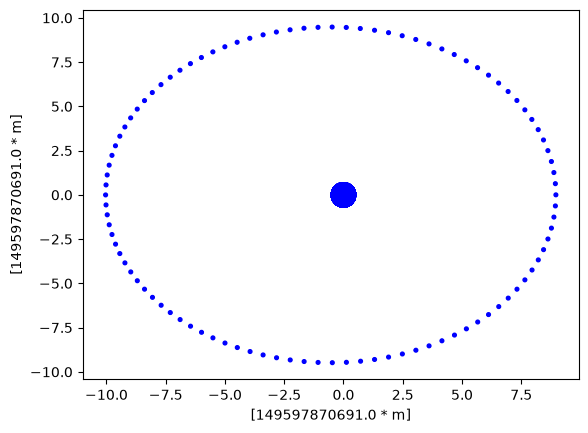

In [ ]:
from amuse.lab import *
from amuse.ext.orbital_elements import new_binary_from_orbital_elements
from matplotlib import pyplot as plt
from amuse.plot import scatter
from amuse.ext.orbital_elements import get_orbital_elements_from_binary
from amuse.community.ph4.interface import Ph4
from amuse.ext.orbital_elements import semimajor_axis_to_orbital_period

def initial_conditions():
    #sun = Particle()
    msun = 1.0 | units.MSun
    #sun.name = "Sun"

    #saturn = Particle()
    msaturn = 0.0002857 | units.MSun
    #saturn.name = "Saturn"
    a_saturn = 9.5 | units.AU
    e_saturn = 0.0565
    
    #bodies = Particles()
    #bodies.add_particle(sun)
    #bodies.add_particle(saturn)

    bodies = new_binary_from_orbital_elements( #returns a paired particle set so not need to initialize them as particles anymore
        mass1 = msun, 
        mass2 = msaturn, 
        semimajor_axis = a_saturn, 
        eccentricity = e_saturn, 
        G=constants.G) #dont have to specify G
    bodies.name = ['Sun', 'Saturn']

    miapetus = 1.8e+21 | units.kg
    a_iapetus = 3.5617e+6 | units.km
    e_iapetus = 0.028
    i_binary = new_binary_from_orbital_elements(
        mass1 = msaturn,
        mass2 = miapetus,
        semimajor_axis = a_iapetus,
        eccentricity = e_iapetus,
        G = constants.G)

    i_binary.name = ['Fake Saturn (do not use)', 'Iapetus']
    iapetus = i_binary[i_binary.name == 'Iapetus']
    i_binary.position -= i_binary[0].position #centers the binary on the position of saturn
    i_binary.velocity -= i_binary[0].velocity #centers the binary on the velocity of saturn

    saturn = bodies[bodies.name == 'Saturn']
    iapetus.position += saturn.position
    iapetus.velocity += saturn.velocity
    bodies.add_particles(iapetus)

    #print(iapetus)

    return bodies
#def semi_to_orbital_period(a, Mtot):
    #return 2 * np.pi * (a**3 /constants.G / Mtot)**0.5

if __name__ == "__main__":
    bodies = initial_conditions()

    a = [] | units.AU
    e = []

    print(bodies)
    saturn_orbit = get_orbital_elements_from_binary(bodies[0:2], G=constants.G)
    print(f'saturn orbit: {saturn_orbit}')

    a.append(saturn_orbit[2])
    e.append(saturn_orbit[3])

    iapetus_orbit = get_orbital_elements_from_binary(bodies[1:3], G=constants.G)
    print(f'iapetus orbit: {iapetus_orbit}')
    a.append(iapetus_orbit[2])
    e.append(iapetus_orbit[3])

    #scatter(bodies.x, bodies.y, s = 2+300*np.sqrt(bodies.mass/bodies.mass.sum())) #plot of positions
    #plt.show()

    #scatter(a, e) #plot of orbits
    #plt.show()


    converter = nbody_system.nbody_to_si(bodies.mass.sum(), 1 | units.AU)
    gravity = Ph4(converter)
    gravity.particles.add_particles(bodies) #makes a copy of bodies in the nbody code called gravity
    print(f'gravity.particles: {gravity.particles}')
    print(f'bodies: {bodies}')

    channel_from_gravity = gravity.particles.new_channel_to(bodies) #makes a solid link from the memory in the python script to the memory in the nbody code

    Ek0 = bodies.kinetic_energy()
    Ep0 = bodies.potential_energy()
    Etot = Ek0 + Ep0

    Porb = semimajor_axis_to_orbital_period(a[0], bodies[0:2].mass.sum())
    time = 0 | units.yr
    dt = Porb / 100
    index = 0
    while gravity.model_time < Porb:
        time += dt
        gravity.evolve_model(time)
        channel_from_gravity.copy()
        Ek = bodies.kinetic_energy()
        Ep = bodies.potential_energy()
        print(f'time = {time.in_(units.yr)}, dEtot = {(Ek+Ep-Etot)/Etot}')
        plt.xlim(-10, 10)
        plt.ylim(-10, 10)
        scatter(bodies.x, bodies.y, s = 2+300*np.sqrt(bodies.mass/bodies.mass.sum()), c = 'blue')
        index += 1
        filename = f'snapshot_i{index:04}.jpg' #makes images for the movie. has a lot of image outputs
        plt.savefig(filename)
        plt.close()


    #gravity.evolve_model(2 | units.yr) #evolves the system for 2 years
    #channel_from_gravity.copy() #updates the bodies with the new positions from the gravity code
    #scatter(bodies.x, bodies.y, s = 2+300*bodies.mass/bodies.mass.sum(), c = 'red')
    #plt.show()
    gravity.stop()